# Library Imports

In [1]:
# Importing dependencies
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize, CenteredNorm
import numpy as np
from os.path import join

from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
from astropy.units import Quantity

# Plot formatting
cm = 0.3937008
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["figure.figsize"] = np.array((8*cm, 5*cm))
mpl.rcParams["lines.linewidth"] = 0.2
mpl.rcParams["font.size"] = 5
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["errorbar.capthick"] = 0.2
mpl.rcParams["errorbar.capsize"] = 1.5
mpl.rcParams["lines.markersize"] = 0.1

DATADIR = "/home/brad/OneDrive/UniWork/Year4/DataIntensivePhysics/Repository/SampleData/"

# Dictionary containing all data files
dataDict = {
	  "NIRH": "EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102159484-39CF67_20241024T214009.099906Z_00.00.fits", 
	  "NIRJ": "EUC_MER_BGSUB-MOSAIC-NIR-J_TILE102159484-C026DB_20241024T213141.416722Z_00.00.fits", 
	  "NIRY": "EUC_MER_BGSUB-MOSAIC-NIR-Y_TILE102159484-A9CCA7_20241024T221227.957725Z_00.00.fits", 
	   "VIS": "EUC_MER_BGSUB-MOSAIC-VIS_TILE102159484-116033_20241025T015934.885975Z_00.00.fits", 
	   "CAT": "EUC_MER_FINAL-CAT_TILE102159484-EF6D85_20241026T003047.133877Z_00.00.fits", 
	"CUTOUT": "EUC_MER_FINAL-CUTOUTS-CAT_TILE102159484-73BCF1_20241025T145359.184204Z_00.00.fits", 
	 "MORPH": "EUC_MER_FINAL-MORPH-CAT_TILE102159484-AE979F_20241026T003045.182961Z_00.00.fits", 
	  "GSED": "EUC_PHZ_GALAXYSED__20241120T003959.957136Z_00.00.fits",
	"PHZCAT": "EUC_PHZ_PHZCAT__20241120T003850.158262Z_00.00.fits", 
	  "SSED": "EUC_PHZ_STARSED__20241120T003936.665995Z_00.00.fits", 
	"SPELIN":"EUC_SPE_WIDE-CAT-LIN-102159484_N_20241110T054343.637093Z_00.00.fits", 
	"SPEMOD": "EUC_SPE_WIDE-CAT-MOD-102159484_N_20241110T054509.870865Z_00.00.fits", 
	  "SPEZ": "EUC_SPE_WIDE-CAT-Z-102159484_N_20241110T054253.801351Z_00.00.fits"
}

# Function Definitions

In [2]:
def CropImage(image, centre, height, width):
	"""
	Get a cutout from an input `image` at `centre` with dimensions `width*height`
	"""

	centre = SkyCoord(centre[0], centre[1], unit="deg")
	size = Quantity([height, width], unit="deg")

	return Cutout2D(image[0].data, centre, size, wcs=WCS(image[0].header))

def GetCutout(image, cutout):
	"""
	Get the cropped image from a cutout entry.
	"""
	return CropImage(image, (cutout[1], cutout[2]), abs(cutout[4]-cutout[8]), abs(cutout[3]-cutout[5]))

def ShowCutout(image, cutout):
	"""
	Plot a given cutout from the image
	"""

	# Cropping the image to the cutout box
	croppedImg = GetCutout(image, cutout)

	# Plotting the cropped image
	fig, ax = plt.subplots(subplot_kw=dict(projection=croppedImg.wcs))
	ax.imshow(croppedImg.data, cmap="plasma", norm=LogNorm())
	ax.set_title(cutout[0])
	ax.set_xlabel("Right Ascension")
	ax.set_ylabel("Declination")
	
	return fig, ax

def GetSED(hdul, idx, EBounds=(4500, 10000), EStep=100):

	# Creating empty arrays
	flux = np.empty(55)
	fluxErr = np.empty(55)
	E = np.empty(55)
	EErr = np.ones(55) * EStep/2

	for i, energy in enumerate(range(EBounds[0], EBounds[1], EStep)):
		flux[i] = hdul[1].data[idx][f"FLUX_{energy}_{energy+EStep}"]
		fluxErr[i] = hdul[1].data[idx][f"FLUXERR_{energy}_{energy+EStep}"]
		E[i] = energy + EStep/2

	return E, EErr, flux, fluxErr

def PlotSED(hdul, idx, EBounds=(4500, 10000), EStep=100):

	fig, ax = plt.subplots()

	# Plotting the galactic SED
	E, EErr, flux, fluxErr = GetSED(hdul, idx)
	ax.errorbar(
		E, flux, fluxErr, EErr, fmt="D", c="k"
	)
	ax.set_xlabel("Wavelength ($\\AA$)")
	ax.set_ylabel("Data")
	ax.set_title(hdul[1].data[idx][0])

	return fig, ax

def ShowAllCutouts(cutout, dataDict=dataDict):
	
	wcs = WCS(fits.open(join(DATADIR, f"{dataDict["NIRH"]}"))[0].header)

	fig, axs = plt.subplots(4, 1, subplot_kw=dict(projection=wcs), sharex=True, figsize=(8*cm, 14*cm))

	for (i, filt) in enumerate(["NIRH", "NIRJ", "NIRY", "VIS"]):

		hdul = fits.open(join(DATADIR, f"{dataDict[filt]}"))
		croppedImg = GetCutout(hdul, cutout)
		axs[i].imshow(croppedImg.data, cmap="plasma", norm=LogNorm())
		axs[i].annotate(filt, xy=(1, 1), xycoords='axes fraction',
			xytext=(-5, -5), textcoords='offset points',
            ha='right', va='top', backgroundcolor="w")

		axs[i].set_xlabel("")
		axs[i].set_ylabel("Right Ascension")
		
		axs[i].tick_params(axis="y", direction="in")
		axs[i].tick_params(axis="x", direction="in")
		if i != 3:
			axs[i].tick_params(axis="x", labelbottom=False)
	
	axs[3].set_xlabel("Declination")

	fig.subplots_adjust(hspace=0)

	return fig, axs


# Setup and Filehandling

In [3]:
# Image and cutout files
hdulCutouts = fits.open(join(DATADIR, f"{dataDict["CUTOUT"]}"))
# hdulImage  = fits.open(join(DATADIR, f"{DatadataDictDict[filt]}"))
hdulNIRH = fits.open(join(DATADIR, f"{dataDict["NIRH"]}"))
hdulNIRJ = fits.open(join(DATADIR, f"{dataDict["NIRJ"]}"))
hdulNIRY = fits.open(join(DATADIR, f"{dataDict["NIRY"]}"))
hdulVIS = fits.open(join(DATADIR, f"{dataDict["VIS"]}"))

# Morphology file
hdulMorph = fits.open(join(DATADIR, f"{dataDict["MORPH"]}"))

# SED files
hdulGSED = fits.open(join(DATADIR, f"{dataDict["GSED"]}"))
hdulSSED = fits.open(join(DATADIR, f"{dataDict["SSED"]}"))

hdulCAT = fits.open(join(DATADIR, f"{dataDict["CAT"]}"))

In [8]:
hdulMorph[1].columns

ColDefs(
    name = 'OBJECT_ID'; format = 'K'; unit = 'NA'; null = 9223372036854775807
    name = 'CONCENTRATION'; format = 'E'; unit = 'NA'
    name = 'CONCENTRATION_ERR'; format = 'E'; unit = 'NA'
    name = 'ASYMMETRY'; format = 'E'; unit = 'NA'
    name = 'ASYMMETRY_ERR'; format = 'E'; unit = 'NA'
    name = 'SMOOTHNESS'; format = 'E'; unit = 'NA'
    name = 'SMOOTHNESS_ERR'; format = 'E'; unit = 'NA'
    name = 'GINI'; format = 'E'; unit = 'NA'
    name = 'GINI_ERR'; format = 'E'; unit = 'NA'
    name = 'MOMENT_20'; format = 'E'; unit = 'NA'
    name = 'MOMENT_20_ERR'; format = 'E'; unit = 'NA'
    name = 'SERSIC_VISNIR_REDUCED_CHI2'; format = 'E'; unit = 'NA'
    name = 'SERSIC_VISNIR_ITERATIONS'; format = 'J'; unit = 'NA'; null = 2147483647
    name = 'SERSIC_VISNIR_FLAGS'; format = 'K'; unit = 'NA'; null = 9223372036854775807
    name = 'SERSIC_VISNIR_DURATION'; format = 'E'; unit = 's'
    name = 'SERSIC_SERSIC_VIS_RADIUS'; format = 'E'; unit = 'arcsec'
    name = 'SERSIC_SERS

In [5]:
# Extracting the same column from the galaxy and star SED files
gData = hdulGSED[1].data
sData = hdulSSED[1].data

gFlux = gData["FLUX_4500_4600"]
sFlux = sData["FLUX_4500_4600"]
allIndices = np.arange(0, len(gFlux))

# Filtering to find what objects have data in both the galaxy and star SED dataset
condition = (np.invert(np.isnan(gFlux)) & np.invert(np.isnan(sFlux)))

# Counting the number of objects that have data for both a galaxy and star SED
nBoth = np.count_nonzero(condition)

# Taking the row indices 
idxs = allIndices[condition]

# Counting the number of objects that have each SED
nStars = len(sFlux) - np.count_nonzero(np.isnan(sFlux))
nGalaxies = len(gFlux) - np.count_nonzero(np.isnan(gFlux))

print(f"Of the {len(sFlux)} objects:")
print(f"    {round(100*nStars/len(sFlux), 1)}% ({nStars}) have a stellar SED")
print(f"    {round(100*nGalaxies/len(gFlux), 1)}% ({nGalaxies}) have a galactic SED")
print(f"    {nBoth} have both a stellar and galactic SED, at indices {idxs}")
print(f"    This is {round(100*nBoth/nStars, 1)}% of the stellar samples and {round(100*nBoth/nGalaxies, 1)}% of the galactic samples")

Of the 111422 objects:
    1.8% (1963) have a stellar SED
    52.0% (57919) have a galactic SED
    1963 have both a stellar and galactic SED, at indices [   74    80   147 ... 83830 83868 83894]
    This is 100.0% of the stellar samples and 3.4% of the galactic samples


PHZ_GAL_PROB    : 0.0071 (threshold 0.2205)
PHZ_STAR_PROB   : 0.9954 (threshold 0.5814)
PHZ_QSO_PROB    : 0.0139 (threshold 0.6687)
PHZ_GLOB_CL_PROB: 0.0000 (threshold 1.0000)


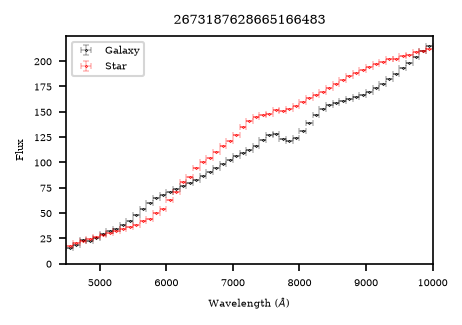

In [6]:
idx=np.random.choice(idxs)
columns = hdulGSED[1].columns

# Which object (row index) to use
gData = hdulGSED[1].data[idx]
sData = hdulSSED[1].data[idx]

for i in range(0, 8, 2):
	print(f"{columns[i-8].name:<16}: {sData[i-8]:.4f} (threshold {sData[i-7]:.4f})")

fig, ax = plt.subplots()

# Plotting the galactic SED
E, EErr, flux, fluxErr = GetSED(hdulGSED, idx)
ax.errorbar(
	E, flux, fluxErr, EErr, 
	label="Galaxy", c="k", fmt="D"
)

# Plotting the stellar SED
E, EErr, flux, fluxErr = GetSED(hdulSSED, idx)
ax.errorbar(
	E, flux, fluxErr, EErr, 
	label="Star", c="r", fmt="D"
)

ax.set_xlabel("Wavelength ($\\AA$)")
ax.set_xlim(4500, 10000)
ax.set_ylim(0, None)
ax.set_ylabel("Flux")
ax.set_title(sData[0])
ax.legend()

Object Unknown


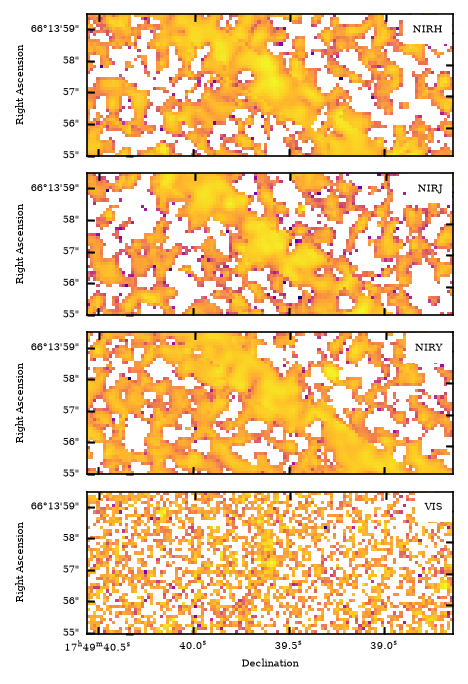

In [7]:
idx = np.random.choice(allIndices)
#[np.invert(np.isnan(gFlux))]
ShowAllCutouts(hdulCutouts[1].data[idx])

if np.invert(np.isnan(gFlux))[idx]:
    print("Object is a Galaxy")
    PlotSED(hdulGSED, idx)
elif np.invert(np.isnan(sFlux))[idx]:
    print("Object is a Star")
    PlotSED(hdulSSED, idx)
else: 
    print("Object Unknown")